# COPD - LazyPredict (which model is best?)

LazyPredict trains many models with default settings and ranks them, so we do not have to guess.

Input: `COPD_clean.csv` from `COPD_EDA_Cleaning.ipynb` (run that notebook first).
* The **training** set is balanced (under-sampling) so the models do not just answer "no COPD".
* The **test** set is untouched (natural 8% COPD).

Note: LazyPredict scores use hard 0/1 predictions (its "ROC AUC" column is computed from them), so it is
a first filter only. After it, we re-score the best models with real probabilities (ROC-AUC / PR-AUC).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time
import pandas as pd
import lightgbm as lgb
from catboost import CatBoostClassifier
from lazypredict.Supervised import LazyClassifier
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import (LogisticRegression, PassiveAggressiveClassifier, Perceptron,
                                  RidgeClassifier, SGDClassifier)
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.naive_bayes import BernoulliNB, GaussianNB
from sklearn.neighbors import NearestCentroid
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier

from copd_data import balance, get_train_test

X_train, X_test, y_train, y_test = get_train_test()
Xb, yb = balance(X_train, y_train)
print("train (balanced):", Xb.shape, "COPD share:", round(yb.mean(), 2))
print("test (natural)  :", X_test.shape, "COPD share:", round(y_test.mean(), 3))

train (balanced): (59074, 6) COPD share: 0.5
test (natural)  : (91100, 6) COPD share: 0.081


## Run LazyPredict

Very slow models on 59k rows (SVC, NuSVC, KNN, LabelSpreading, stacking...) are left out of the list.

In [2]:
models = [AdaBoostClassifier, BaggingClassifier, BernoulliNB, DecisionTreeClassifier, DummyClassifier,
          ExtraTreeClassifier, ExtraTreesClassifier, GaussianNB, GradientBoostingClassifier,
          HistGradientBoostingClassifier, LinearDiscriminantAnalysis, LinearSVC, LogisticRegression,
          NearestCentroid, PassiveAggressiveClassifier, Perceptron, QuadraticDiscriminantAnalysis,
          RandomForestClassifier, RidgeClassifier, SGDClassifier,
          lgb.LGBMClassifier, CatBoostClassifier]

t0 = time.time()
clf = LazyClassifier(verbose=0, ignore_warnings=True, classifiers=models, random_state=42)
scores = clf.fit(Xb, X_test, yb, y_test)
scores = scores[0] if isinstance(scores, tuple) else scores
print(f"done in {time.time() - t0:.0f}s")
scores.sort_values("Balanced Accuracy", ascending=False)

done in 33s


,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
HistGradientBoostingClassifier,0.742821,0.751342,0.824180,0.799293,0.910285,0.742821,0.698194
GradientBoostingClassifier,0.745401,0.751140,0.824830,0.801134,0.910126,0.745401,3.179405
LGBMClassifier,0.745181,0.750465,0.824144,0.800964,0.909968,0.745181,0.693116
CatBoostClassifier,0.745807,0.750126,0.822630,0.801404,0.909858,0.745807,7.016444
AdaBoostClassifier,0.749934,0.748421,0.820228,0.804307,0.909274,0.749934,1.108745
LogisticRegression,0.723106,0.731292,0.799547,0.784735,0.906159,0.723106,0.090195
LinearSVC,0.721317,0.731121,0.799547,0.783433,0.906201,0.721317,0.084791
LinearDiscriminantAnalysis,0.720077,0.730940,0.799537,0.782528,0.906215,0.720077,0.235320
RidgeClassifier,0.720077,0.730940,0.799537,0.782528,0.906215,0.720077,0.074408


## Re-score the best models with probabilities

Balanced accuracy on hard predictions depends on the cut-off. A fairer comparison for a risk score is
**ROC-AUC** and **PR-AUC** from the predicted probabilities. We refit the models that have `predict_proba`.

In [3]:
candidates = {
    "LGBMClassifier": lgb.LGBMClassifier(verbosity=-1, random_state=42),
    "CatBoostClassifier": CatBoostClassifier(verbose=False, random_seed=42),
    "HistGradientBoostingClassifier": HistGradientBoostingClassifier(random_state=42),
    "GradientBoostingClassifier": GradientBoostingClassifier(random_state=42),
    "RandomForestClassifier": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "AdaBoostClassifier": AdaBoostClassifier(random_state=42),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "LinearDiscriminantAnalysis": LinearDiscriminantAnalysis(),
    "DecisionTreeClassifier": DecisionTreeClassifier(min_samples_leaf=50, random_state=42),
}
rows = []
for name, m in candidates.items():
    m.fit(Xb, yb)
    p = m.predict_proba(X_test)[:, 1]
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})
final = pd.DataFrame(rows).set_index("model").sort_values("ROC-AUC", ascending=False)
final.round(4)

,ROC-AUC,PR-AUC
model,,
GradientBoostingClassifier,0.8248,0.3333
LGBMClassifier,0.8244,0.3305
HistGradientBoostingClassifier,0.8242,0.3304
CatBoostClassifier,0.8227,0.3239
RandomForestClassifier,0.8211,0.3170
AdaBoostClassifier,0.8202,0.3266
DecisionTreeClassifier,0.8119,0.2938
LogisticRegression,0.7995,0.2707
LinearDiscriminantAnalysis,0.7995,0.2710


Best by ROC-AUC: GradientBoostingClassifier | best by PR-AUC: GradientBoostingClassifier


<Axes: title={'center': 'ROC-AUC on the test set'}, ylabel='model'>

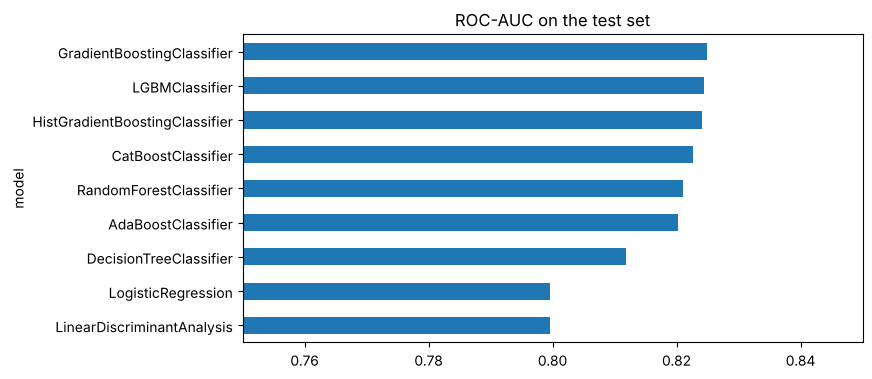

In [4]:
best = final.index[0]
print("Best by ROC-AUC:", best, "| best by PR-AUC:", final["PR-AUC"].idxmax())
final["ROC-AUC"].sort_values().plot(kind="barh", figsize=(8, 4), xlim=(0.75, 0.85), title="ROC-AUC on the test set")

## Conclusion

* Three gradient-boosting models are on top and practically tied: GradientBoosting 0.8248, **LightGBM 0.8244**,
  HistGradientBoosting 0.8242 ROC-AUC. A 0.0004 gap is noise, not a real difference.
* They beat the linear models (Logistic Regression / LDA, about 0.80) by roughly 0.025 ROC-AUC, so the
  relationships in the data are not purely linear. Random Forest and the single trees are behind.
* We pick **LightGBM**: same accuracy as the leader but about 4x faster to train (0.7 s vs 3.2 s here, which matters
  for a grid search), it gives per-patient feature contributions, and the rest of the project already uses it.

Next: `COPD_GridSearch.py` finds the best LightGBM parameters.